# Exploratory Data Analysis

In [2]:
# import important libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# Better looking graphs

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("../data/cleaned_fake_job_postings.csv")

In [4]:
df["employment_type_display"] = df["employment_type"].fillna("Not Specified")
df["required_experience_display"] = df["required_experience"].fillna("Not Specified")
df["required_education_display"] = df["required_education"].fillna("Not Specified")
df["industry_display"] = df["industry"].fillna("Not Specified")
df["function_display"] = df["function"].fillna("Not Specified")

### Target Variable Distribution

<function matplotlib.pyplot.show(close=None, block=None)>

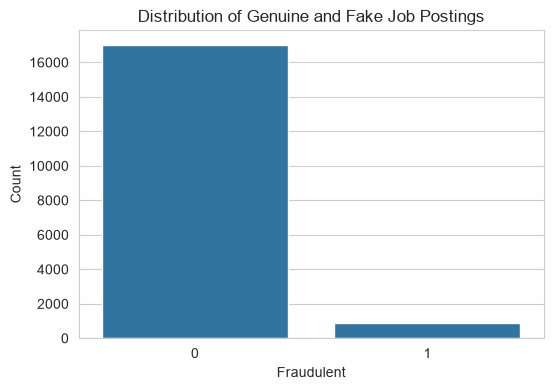

In [5]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="fraudulent"
)

plt.title("Distribution of Genuine and Fake Job Postings")

plt.xlabel("Fraudulent")

plt.ylabel("Count")

plt.show

### Target Variable Analysis

In [6]:
# Count the number of genuine or fake job postings

target_counts = df["fraudulent"].value_counts()

target_counts

fraudulent
0    17014
1      866
Name: count, dtype: int64

### Calculate Percentage

In [7]:
# Percentage of each class

target_percentage = df["fraudulent"].value_counts(normalize=True) * 100

target_percentage

fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64

### Summary Table

In [8]:
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentage
})

target_summary

,Count,Percentage
fraudulent,,
0,17014,95.1566
1,866,4.8434


<function matplotlib.pyplot.show(close=None, block=None)>

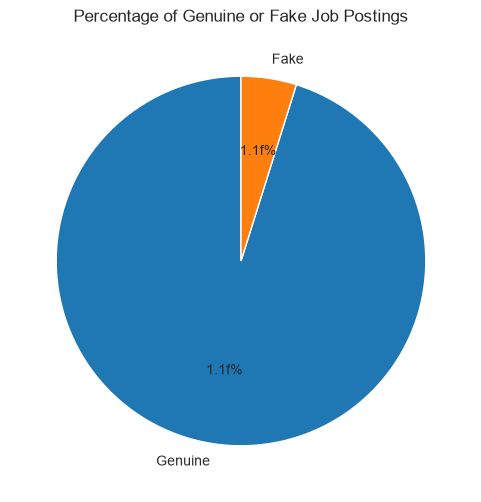

In [9]:
# Create a Pie Chart

plt.figure(figsize=(6,6))


plt.pie(
    target_counts,
    labels=["Genuine","Fake"],
    autopct="1.1f%%",
    startangle=90
)

plt.title("Percentage of Genuine or Fake Job Postings")

plt.show

### Employment Type Analysis

In [10]:
# Count employment types

employment_counts = df["employment_type_display"].value_counts()

employment_counts

employment_type_display
Full-time        11620
Not Specified     3471
Contract          1524
Part-time          797
Temporary          241
Other              227
Name: count, dtype: int64

In [11]:
employment_display = df["employment_type"].fillna("Not Specified")

employment_display = df["employment_type_display"]

### Visualize Employment Types

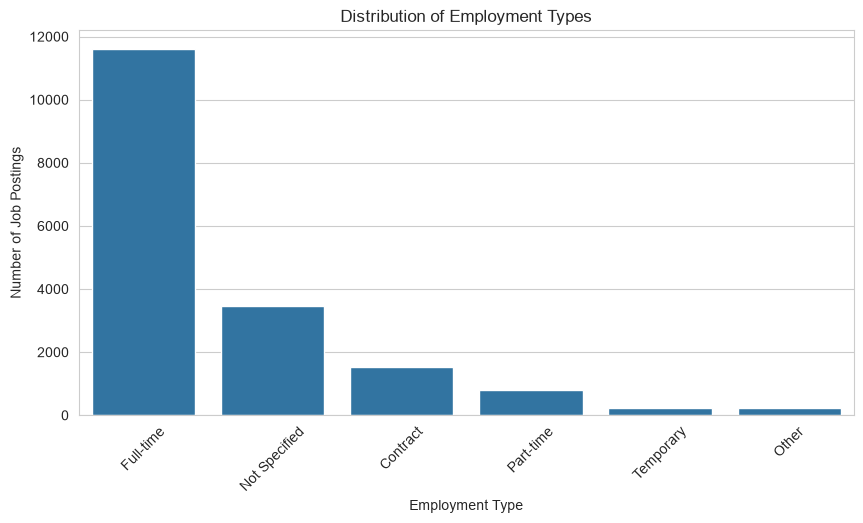

In [12]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="employment_type_display",
    order=employment_display.value_counts().index
)

plt.title("Distribution of Employment Types")

plt.xlabel("Employment Type")

plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45)

plt.show()

### Employment Type VS Fraudulent

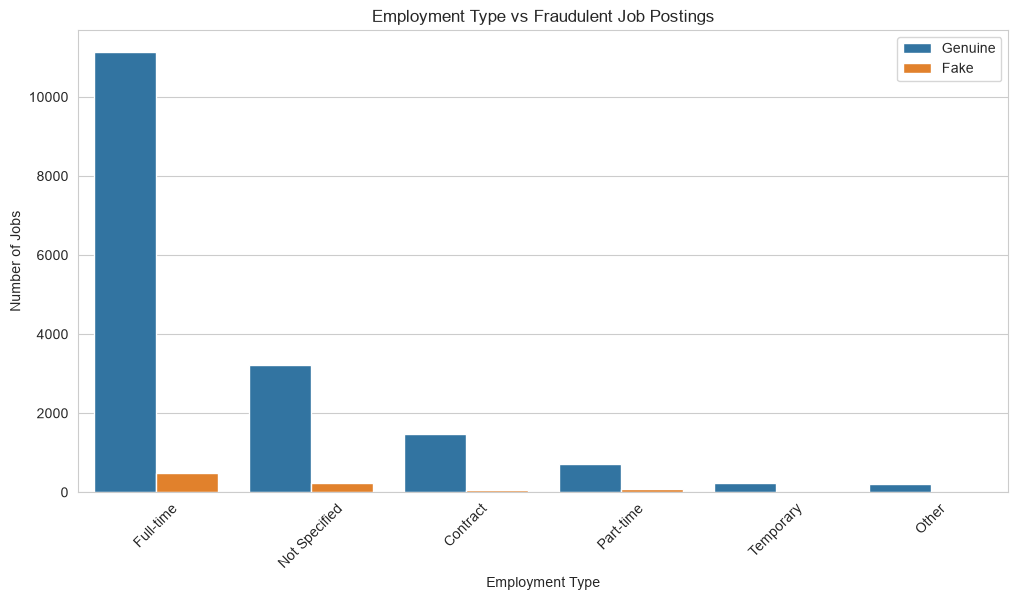

In [13]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x="employment_type_display",
    hue="fraudulent",
    order=df["employment_type_display"].value_counts().index
)

plt.title("Employment Type vs Fraudulent Job Postings")
plt.xlabel("Employment Type")
plt.ylabel("Number of Jobs")

plt.legend(["Genuine", "Fake"])

plt.xticks(rotation=45)

plt.show()

In [14]:
# Create a cross table

employment_fraud = pd.crosstab(
    employment_display,
    df["fraudulent"]
)

employment_fraud

fraudulent,0,1
employment_type_display,,
Contract,1480,44
Full-time,11130,490
Not Specified,3230,241
Other,212,15
Part-time,723,74
Temporary,239,2


In [15]:
# Percentage Table
employment_percentage = pd.crosstab(
    employment_display,
    df["fraudulent"],
    normalize="index"
) * 100

employment_percentage

fraudulent,0,1
employment_type_display,,
Contract,97.112861,2.887139
Full-time,95.783133,4.216867
Not Specified,93.056756,6.943244
Other,93.392070,6.607930
Part-time,90.715182,9.284818
Temporary,99.170124,0.829876
